## 0. Setup

In [1]:
import os
from typing import Dict, Any
from IPython.display import Image, display
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.agents.middleware import wrap_model_call
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import MessagesState
from langgraph_supervisor import create_handoff_tool
from langgraph_supervisor.handoff import create_handoff_back_messages

In [2]:
load_dotenv()

True

In [3]:
llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0.0,
    base_url="https://openai.vocareum.com/v1",
    api_key=os.getenv("VOCAREUM_API_KEY")
)

## 1. Sub Agents

In [4]:
research_worker = create_agent(
    name="research_worker",
    system_prompt=SystemMessage(
        content=(
            "You are a research specialist. Given a topic, find key information. "
            "Return ONLY JSON with: keywords, sources."
        )
    ),
    model=llm,
    tools=[],
)

In [5]:
writing_worker = create_agent(
    name="writing_worker",
    system_prompt=SystemMessage(
        content=(
            "You are a content writer. " 
            "Given research keywords, write clear and concise content. "
            "Return ONLY JSON with: content, summary."
        )
    ),
    model=llm,
    tools=[],
)

## 2. Orchestrator

In [6]:
@wrap_model_call
def one_handoff_at_a_time(request, handler):
    return handler(request.override(
        model_settings={**request.model_settings, "parallel_tool_calls": False},
    ))


def worker_node(worker, supervisor_name):
    def run(state):
        result = worker.invoke(state)
        return {"messages": [
            result["messages"][-1],
            *create_handoff_back_messages(worker.name, supervisor_name),
        ]}

    return run


def build_supervisor(agents, supervisor_name="supervisor", system_prompt=None):
    worker_names = tuple(agent.name for agent in agents)
    supervisor = create_agent(
        model=llm,
        tools=[create_handoff_tool(agent_name=name) for name in worker_names],
        system_prompt=system_prompt,
        middleware=[one_handoff_at_a_time],
        name=supervisor_name,
    )
    workflow = StateGraph(MessagesState)
    workflow.add_node(supervisor_name, supervisor, destinations=(*worker_names, END))
    workflow.add_edge(START, supervisor_name)
    for worker in agents:
        workflow.add_node(worker.name, worker_node(worker, supervisor_name))
        workflow.add_edge(worker.name, supervisor_name)
    return workflow


supervisor_agent = build_supervisor(
    agents=[research_worker, writing_worker],
    system_prompt=(
        "You are a task supervisor. When given a request:\n"
        "1. First use transfer_to_research_worker to gather information.\n"
        "2. Then use transfer_to_writing_worker to create content based on the research.\n"
        "3. Combine the workers' replies into a final response."
    ),
).compile()

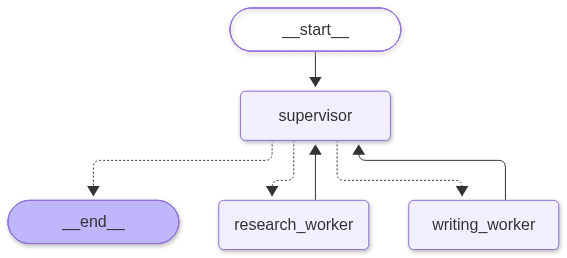

In [7]:
display(
    Image(
        supervisor_agent.get_graph().draw_mermaid_png()
    )
)

## 4. Run

In [8]:
result = supervisor_agent.invoke(
    input={
        "messages": [
            HumanMessage(
                content="topic machine learning basics"
            )
        ]
    }
)

In [9]:
for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

topic machine learning basics
================================== Ai Message ==================================
Name: supervisor
Tool Calls:
  transfer_to_research_worker (call_2uOdcvt75iNLKuLgJVu7kzwv)
 Call ID: call_2uOdcvt75iNLKuLgJVu7kzwv
  Args:
================================= Tool Message =================================
Name: transfer_to_research_worker

Successfully transferred to research_worker
================================== Ai Message ==================================
Name: research_worker

{
  "keywords": [
    "machine learning",
    "supervised learning",
    "unsupervised learning",
    "reinforcement learning",
    "algorithms",
    "data preprocessing",
    "features",
    "model training",
    "overfitting",
    "underfitting",
    "evaluation metrics",
    "cross-validation",
    "neural networks",
    "decision trees",
    "support vector machines",
    "clustering",
    "regres

## 5. Hierarchical

In [10]:
team_1 = build_supervisor(
    agents=[
        create_agent(name="agent_1", model=llm, tools=[]), 
        create_agent(name="agent_2", model=llm, tools=[]), 
    ],
    supervisor_name="supervisor_1"
).compile(name="team_1")

team_2 = build_supervisor(
    agents=[
        create_agent(name="agent_3", model=llm, tools=[]), 
        create_agent(name="agent_4", model=llm, tools=[]), 
    ],
    supervisor_name="supervisor_2"
).compile(name="team_2")


top_level_supervisor = build_supervisor(
    agents=[team_1, team_2],
    supervisor_name="top_level_supervisor"
).compile(name="top_level_supervisor")

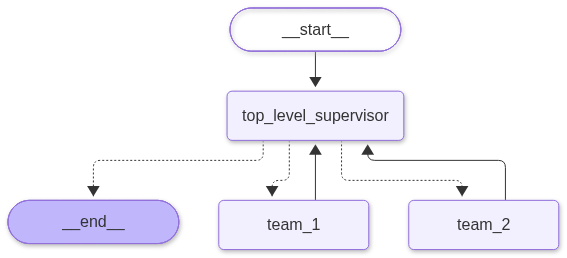

In [11]:
display(
    Image(
        top_level_supervisor.get_graph().draw_mermaid_png()
    )
)